Evaluated sentences: 6
Average score: 10.833333333333334

Average score per criterion:
meaning         2.666667
terminology     2.833333
fluency         2.333333
completeness    3.000000
dtype: float64


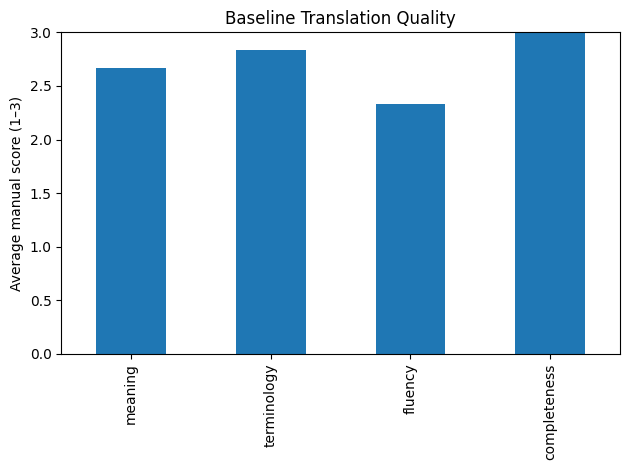

In [9]:

import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv("manual_evaluation_de_en.csv", sep=";")

criteria = [
    "meaning",
    "terminology",
    "fluency",
    "completeness",
]

# Convert manually entered scores to numeric values
df[criteria] = df[criteria].apply(
    pd.to_numeric, errors="coerce"
)

# Only include fully reviewed translations
reviewed = df.dropna(subset=criteria).copy()

reviewed["total_score"] = reviewed[criteria].sum(axis=1)

print("Evaluated sentences:", len(reviewed))
print("Average score:", reviewed["total_score"].mean())

print("\nAverage score per criterion:")
print(reviewed[criteria].mean())

reviewed[criteria].mean().plot(kind="bar")
plt.title("Baseline Translation Quality")
plt.ylabel("Average manual score (1–3)")
plt.ylim(0, 3)
plt.tight_layout()
plt.show()


In [1]:
from pathlib import Path
import pandas as pd

for path in Path("data/processed").rglob("*test.csv"):
    df = pd.read_csv(path)

    print(f"\nDataset: {path}")
    print(f"Rows: {len(df)}")
    print(f"Columns: {df.columns.tolist()}")
    print(df.head(2))